--- Mean Recovery Time by Weight ---
weight
0.2    705.0
0.5    722.0
0.8    777.0
Name: recovery_ticks, dtype: float64


--- Kruskal-Wallis H-test ---
H-statistic: 2.00, p-value: 0.3679


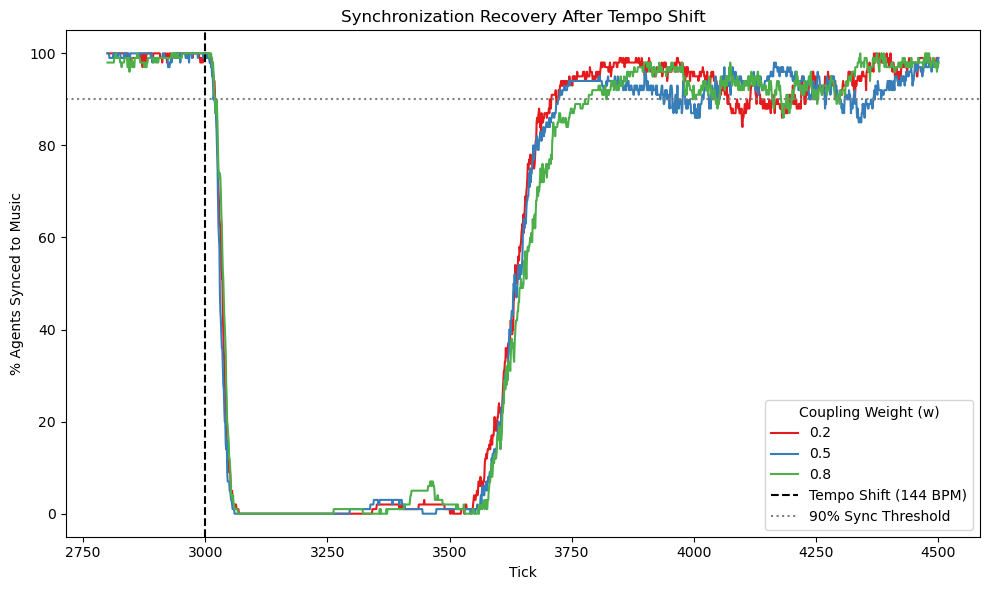

In [2]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Define your exact OneDrive working directory
work_dir = "/Users/rutgersmac/Library/CloudStorage/OneDrive-TilburgUniversity/CSAI/Year 2/Y2 S1/Multi-Agent Systems/new project/WD_Experiments_Analysis"

# 1. Load Data 
csv_path = os.path.join(work_dir, "AgentSyncModelVol.3 TempoShift_Experiment-table.csv")
df = pd.read_csv(csv_path, skiprows=6)

# Rename the verbose NetLogo reporters to clean Python variables
df = df.rename(columns={
    '[run number]': 'run_id',
    'w': 'weight',
    '[step]': 'tick',
    '(count turtles with [abs wrap-error (music-phase - phase) <= 0.1] / count turtles) * 100': 'pct_synced',
    'mean [ abs wrap-error (music-phase - phase) ] of turtles': 'music_alignment',
    'sqrt ((mean [sin (phase * 360)] of turtles ^ 2) + (mean [cos (phase * 360)] of turtles ^ 2))': 'coherence'
})

# 2. Define the Primary Dependent Variable (Recovery Time)
def get_robust_recovery_time(group):
    # Filter to only look at ticks after the tempo shift at 3000
    post_shift = group[group['tick'] > 3000]
    
    # Find the tick where synchronization hits absolute rock bottom
    min_sync_val = post_shift['pct_synced'].min()
    nadir_tick = post_shift[post_shift['pct_synced'] == min_sync_val]['tick'].min()
    
    # Find the first tick it recovers to >= 90% AFTER hitting rock bottom
    recovery_points = post_shift[(post_shift['tick'] > nadir_tick) & (post_shift['pct_synced'] >= 90)]
    
    if recovery_points.empty:
        return np.nan # Did not recover within the 9000 tick limit
        
    return recovery_points['tick'].iloc[0] - 3000

# Apply the function to get the recovery time per run
recovery_data = df.groupby(['weight', 'run_id']).apply(get_robust_recovery_time).reset_index(name='recovery_ticks')

# Print the mean recovery time for each experimental condition
print("--- Mean Recovery Time by Weight ---")
print(recovery_data.groupby('weight')['recovery_ticks'].mean())
print("\n")

# 3. Statistical Analysis (Kruskal-Wallis Test for non-parametric variance)
w02 = recovery_data[recovery_data['weight'] == 0.2]['recovery_ticks'].dropna()
w05 = recovery_data[recovery_data['weight'] == 0.5]['recovery_ticks'].dropna()
w08 = recovery_data[recovery_data['weight'] == 0.8]['recovery_ticks'].dropna()

stat, p = stats.kruskal(w02, w05, w08)
print("--- Kruskal-Wallis H-test ---")
print(f"H-statistic: {stat:.2f}, p-value: {p:.4f}")

# 4. Visualization for the Results Section
plot_data = df[(df['tick'] >= 2800) & (df['tick'] <= 4500)]

plt.figure(figsize=(10, 6))
sns.lineplot(data=plot_data, x='tick', y='pct_synced', hue='weight', palette='Set1', errorbar=None)
plt.axvline(3000, color='black', linestyle='--', label='Tempo Shift (144 BPM)')
plt.axhline(90, color='gray', linestyle=':', label='90% Sync Threshold')

plt.title('Synchronization Recovery After Tempo Shift')
plt.ylabel('% Agents Synced to Music')
plt.xlabel('Tick')
plt.legend(title='Coupling Weight (w)')
plt.tight_layout()

# Save the high-res plot directly to your OneDrive folder for the report
plot_path = os.path.join(work_dir, "recovery_plot.png")
plt.savefig(plot_path, dpi=300)
plt.show()


Loaded file: 100 repititions experiment.csv (142.59 MB)

=== DESCRIPTIVE STATISTICS (RECOVERY TICKS) ===
          N    Mean     SD  Median   IQR  Min  Max
weight                                            
0.2     100  721.85  37.94   709.5  31.5  681  927
0.5     100  729.00  43.87   714.5  39.0  675  920
0.8     100  717.10  31.80   708.0  25.0  676  869

Total runs analyzed: 300 | Unrecovered runs (NaN): 0

=== NORMALITY CHECK (SHAPIRO-WILK) ===
w = 0.2: W = 0.7472, p = 7.8942e-12
w = 0.5: W = 0.8405, p = 5.3654e-09
w = 0.8: W = 0.7727, p = 3.8955e-11

=== INFERENTIAL TESTS ===
Kruskal-Wallis: H = 3.2237, p = 1.9952e-01, epsilon^2 = 0.0108
One-Way ANOVA:  F = 2.4605, p = 8.7135e-02, eta^2 = 0.0163


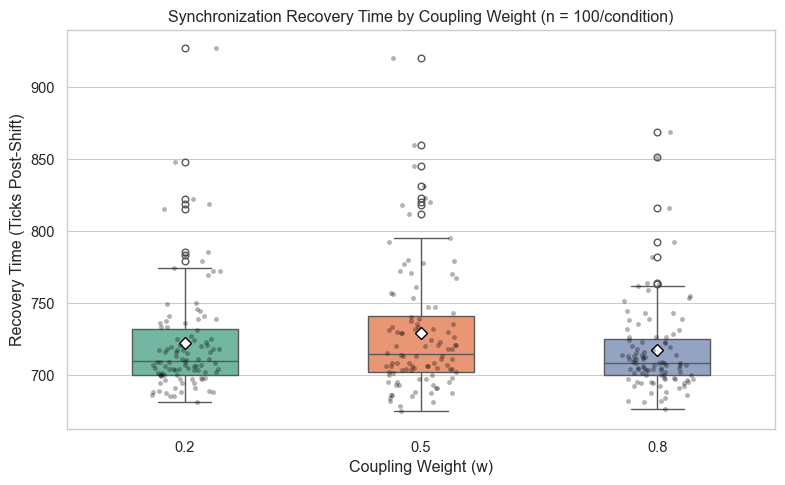

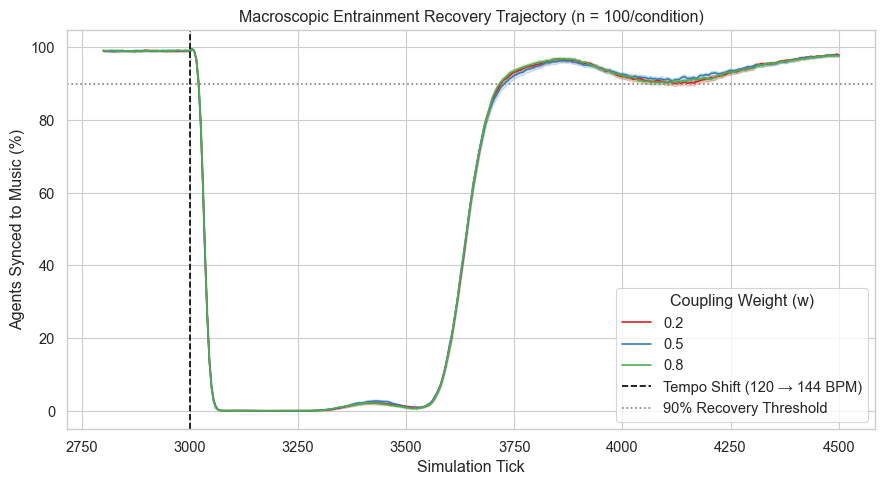

In [9]:
import os
import csv
import glob
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Locate the 100-repetitions CSV in your working directory
work_dir = "/Users/rutgersmac/Library/CloudStorage/OneDrive-TilburgUniversity/CSAI/Year 2/Y2 S1/Multi-Agent Systems/new project/WD_Experiments_Analysis"

matches = glob.glob(os.path.join(work_dir, "*100*experiment*.csv"))
csv_path = max(matches, key=os.path.getmtime) if matches else max(glob.glob(os.path.join(work_dir, "*.csv")), key=os.path.getmtime)
print(f"Loaded file: {os.path.basename(csv_path)} ({os.path.getsize(csv_path) / (1024**2):.2f} MB)\n")

# 2. Parse NetLogo BehaviorSpace 'Spreadsheet' metadata headers
meta_rows = []
with open(csv_path, "r", encoding="utf-8", errors="ignore", newline="") as f:
    reader = csv.reader(f)
    for _ in range(35):
        try:
            meta_rows.append(next(reader))
        except StopIteration:
            break

row_labels = [r[0].strip() if len(r) > 0 else "" for r in meta_rows]

if "[run number]" not in row_labels or "[all run data]" not in row_labels:
    raise ValueError("Could not find '[run number]' or '[all run data]' headers in the CSV.")

run_row_idx = row_labels.index("[run number]")
w_row_idx = row_labels.index("w")
all_data_idx = row_labels.index("[all run data]")
rep_row_idx = row_labels.index("[reporter]") if "[reporter]" in row_labels else None

run_row = meta_rows[run_row_idx]
w_row = meta_rows[w_row_idx]
rep_row = meta_rows[rep_row_idx] if rep_row_idx is not None else []
max_cols = max(len(r) for r in meta_rows)

# Map each run's pct_synced column index to its (weight, run_id)
target_cols = []
col_meta = {}
curr_run = None
curr_w = None

for col_idx in range(1, max_cols):
    r_str = run_row[col_idx].strip() if col_idx < len(run_row) else ""
    if r_str != "":
        curr_run = int(float(r_str))
    if col_idx < len(w_row) and w_row[col_idx].strip() != "":
        curr_w = float(w_row[col_idx].strip())

    if rep_row_idx is not None:
        rep_str = rep_row[col_idx].strip() if col_idx < len(rep_row) else ""
        if "wrap-error" in rep_str and "100" in rep_str:
            target_cols.append(col_idx)
            col_meta[col_idx] = (curr_w, curr_run)
    elif r_str != "":
        target_cols.append(col_idx)
        col_meta[col_idx] = (curr_w, curr_run)

# Fallback: if reporter text didn't match, take the first column of each run
if not target_cols:
    curr_w = None
    for col_idx in range(1, max_cols):
        if col_idx < len(w_row) and w_row[col_idx].strip() != "":
            curr_w = float(w_row[col_idx].strip())
        r_str = run_row[col_idx].strip() if col_idx < len(run_row) else ""
        if r_str != "":
            target_cols.append(col_idx)
            col_meta[col_idx] = (curr_w, int(float(r_str)))

# 3. Load only the synchronization columns across all ticks (names=range(max_cols) avoids ragged-row IndexError)
ts_df = pd.read_csv(
    csv_path,
    skiprows=all_data_idx + 1,
    names=range(max_cols),
    usecols=target_cols,
    header=None
)
ts_df = ts_df.apply(pd.to_numeric, errors="coerce").dropna(how="all").reset_index(drop=True)

# Compute post-shift Recovery Time per run
records = []
for col_idx in target_cols:
    w_val, r_id = col_meta[col_idx]
    post = ts_df.loc[ts_df.index > 3000, col_idx]
    min_sync = post.min()
    nadir_tick = post[post == min_sync].index.min()
    rec_points = post[(post.index > nadir_tick) & (post >= 90)]
    rec_ticks = np.nan if rec_points.empty else (rec_points.index[0] - 3000)
    records.append({"weight": w_val, "run_id": r_id, "recovery_ticks": rec_ticks})

recovery_df = pd.DataFrame(records)

# 4. Descriptive Statistics
summary = recovery_df.groupby("weight")["recovery_ticks"].agg(
    N="count",
    Mean="mean",
    SD="std",
    Median="median",
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    Min="min",
    Max="max"
).round(2)

print("=== DESCRIPTIVE STATISTICS (RECOVERY TICKS) ===")
print(summary)
print(f"\nTotal runs analyzed: {len(recovery_df)} | Unrecovered runs (NaN): {recovery_df['recovery_ticks'].isna().sum()}\n")

# 5. Inferential Statistics & Post-Hoc Comparisons
weights = sorted(recovery_df["weight"].unique())
groups = [recovery_df[recovery_df["weight"] == w]["recovery_ticks"].dropna().values for w in weights]

print("=== NORMALITY CHECK (SHAPIRO-WILK) ===")
for w_val, vals in zip(weights, groups):
    w_stat, p_norm = stats.shapiro(vals[:5000])
    print(f"w = {w_val}: W = {w_stat:.4f}, p = {p_norm:.4e}")

h_stat, p_kw = stats.kruskal(*groups)
n_total = sum(len(g) for g in groups)
eps_sq = h_stat / (n_total - 1)

f_stat, p_anova = stats.f_oneway(*groups)
grand_mean = np.concatenate(groups).mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = sum(((g - grand_mean) ** 2).sum() for g in groups)
eta_sq = ss_between / ss_total

print("\n=== INFERENTIAL TESTS ===")
print(f"Kruskal-Wallis: H = {h_stat:.4f}, p = {p_kw:.4e}, epsilon^2 = {eps_sq:.4f}")
print(f"One-Way ANOVA:  F = {f_stat:.4f}, p = {p_anova:.4e}, eta^2 = {eta_sq:.4f}")

if p_kw < 0.05:
    print("\n=== POST-HOC PAIRWISE MANN-WHITNEY U (BONFERRONI CORRECTED) ===")
    for i, j in [(0, 1), (0, 2), (1, 2)]:
        u_stat, p_pair = stats.mannwhitneyu(groups[i], groups[j], alternative="two-sided")
        p_adj = min(p_pair * 3, 1.0)
        print(f"w = {weights[i]} vs w = {weights[j]}: U = {u_stat:.1f}, p_adj = {p_adj:.4e}")

# 6. Publication-Ready Visualizations (300 DPI)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
n_per_group = int(summary["N"].iloc[0])

# Plot A: Boxplot + Mean Diamond + Individual Run Points
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=recovery_df, x="weight", y="recovery_ticks",
    hue="weight", palette="Set2", width=0.45, legend=False, showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6}
)
sns.stripplot(
    data=recovery_df, x="weight", y="recovery_ticks",
    color="black", alpha=0.3, size=3.5, jitter=0.15
)
plt.title(f"Synchronization Recovery Time by Coupling Weight (n = {n_per_group}/condition)")
plt.xlabel("Coupling Weight (w)")
plt.ylabel("Recovery Time (Ticks Post-Shift)")
plt.tight_layout()
plt.savefig(os.path.join(work_dir, "recovery_boxplot_100reps.png"), dpi=300)
plt.show()

# Plot B: Macroscopic Entrainment Trajectory with 95% CI
vis_slice = ts_df.loc[2800:4500:5, target_cols].copy()
vis_slice.index.name = "tick"
df_vis = vis_slice.reset_index().melt(id_vars="tick", var_name="col_idx", value_name="pct_synced")
df_vis["weight"] = df_vis["col_idx"].map(lambda c: col_meta[c][0])

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=df_vis, x="tick", y="pct_synced", hue="weight",
    palette="Set1", errorbar=("ci", 95)
)
plt.axvline(3000, color="black", linestyle="--", label="Tempo Shift (120 → 144 BPM)")
plt.axhline(90, color="gray", linestyle=":", label="90% Recovery Threshold")
plt.title(f"Macroscopic Entrainment Recovery Trajectory (n = {n_per_group}/condition)")
plt.xlabel("Simulation Tick")
plt.ylabel("Agents Synced to Music (%)")
plt.legend(title="Coupling Weight (w)")
plt.tight_layout()
plt.savefig(os.path.join(work_dir, "recovery_trajectory_100reps.png"), dpi=300)
plt.show()


Loaded file: Heterogeneous_100reps.csv (31.24 MB)

=== HETEROGENEOUS MODEL: DESCRIPTIVE STATISTICS (RECOVERY TICKS) ===
          N     Mean      SD  Median     IQR   Min   Max
weight                                                  
0.2     100  1466.77  221.53  1450.0  327.25  1031  2143
0.5     100  1460.46  219.41  1426.0  234.00  1012  2371
0.8     100  1441.05  201.70  1432.0  294.00  1057  2143

Total runs analyzed: 300 | Unrecovered runs (NaN): 0

=== NORMALITY CHECK (SHAPIRO-WILK) ===
w = 0.2: W = 0.9791, p = 1.1345e-01
w = 0.5: W = 0.9541, p = 1.5494e-03
w = 0.8: W = 0.9800, p = 1.3380e-01

=== INFERENTIAL TESTS ===
Kruskal-Wallis: H = 0.4359, p = 8.0415e-01, epsilon^2 = 0.0015
One-Way ANOVA:  F = 0.3909, p = 6.7680e-01, eta^2 = 0.0026


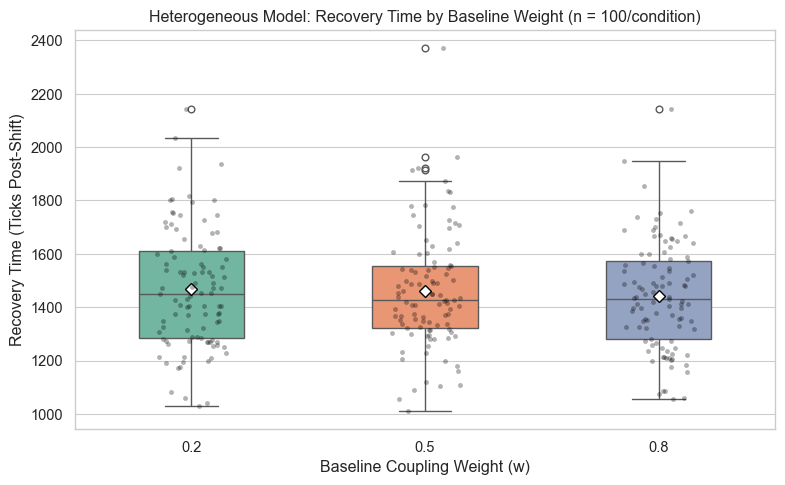

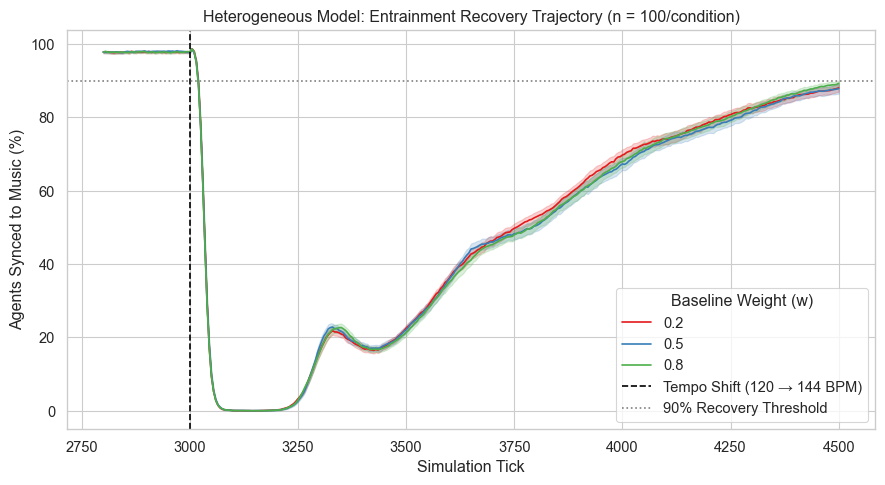

In [10]:
import os
import csv
import glob
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Automatically locate the newest CSV in WD_Experiments_Analysis
work_dir = "/Users/rutgersmac/Library/CloudStorage/OneDrive-TilburgUniversity/CSAI/Year 2/Y2 S1/Multi-Agent Systems/new project/WD_Experiments_Analysis"
csv_files = glob.glob(os.path.join(work_dir, "*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {work_dir}")

csv_path = max(csv_files, key=os.path.getmtime)
print(f"Loaded file: {os.path.basename(csv_path)} ({os.path.getsize(csv_path) / (1024**2):.2f} MB)\n")

# 2. Detect export format (Table vs. Spreadsheet) and compute Recovery Time
meta_rows = []
with open(csv_path, "r", encoding="utf-8", errors="ignore", newline="") as f:
    reader = csv.reader(f)
    for _ in range(35):
        try:
            meta_rows.append(next(reader))
        except StopIteration:
            break

row_labels = [r[0].strip() if len(r) > 0 else "" for r in meta_rows]
run_row_idx = row_labels.index("[run number]")
is_table_format = "[step]" in [c.strip() for c in meta_rows[run_row_idx]]

if is_table_format:
    header_cols = [c.strip() for c in meta_rows[run_row_idx]]
    sync_col = [c for c in header_cols if "wrap-error" in c and "100" in c][0]
    use_cols = ["[run number]", "w", "[step]", sync_col]

    post_chunks, vis_chunks = [], []
    for chunk in pd.read_csv(csv_path, skiprows=run_row_idx, usecols=use_cols, chunksize=500_000):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.rename(columns={
            "[run number]": "run_id",
            "w": "weight",
            "[step]": "tick",
            sync_col: "pct_synced"
        })
        post_chunks.append(chunk[chunk["tick"] > 3000])
        vis_chunks.append(chunk[(chunk["tick"] >= 2800) & (chunk["tick"] <= 4500) & (chunk["tick"] % 5 == 0)])

    df_post = pd.concat(post_chunks, ignore_index=True)
    df_vis = pd.concat(vis_chunks, ignore_index=True)

    records = []
    for (w_val, r_id), group in df_post.groupby(["weight", "run_id"], sort=False):
        min_sync = group["pct_synced"].min()
        nadir_tick = group.loc[group["pct_synced"] == min_sync, "tick"].min()
        rec_points = group[(group["tick"] > nadir_tick) & (group["pct_synced"] >= 90)]
        rec_ticks = np.nan if rec_points.empty else (rec_points["tick"].iloc[0] - 3000)
        records.append({"weight": w_val, "run_id": r_id, "recovery_ticks": rec_ticks})

    recovery_df = pd.DataFrame(records)
else:
    w_row_idx = row_labels.index("w")
    all_data_idx = row_labels.index("[all run data]")
    rep_row_idx = row_labels.index("[reporter]") if "[reporter]" in row_labels else None

    run_row = meta_rows[run_row_idx]
    w_row = meta_rows[w_row_idx]
    rep_row = meta_rows[rep_row_idx] if rep_row_idx is not None else []
    max_cols = max(len(r) for r in meta_rows)

    target_cols, col_meta = [], {}
    curr_run, curr_w = None, None
    for col_idx in range(1, max_cols):
        r_str = run_row[col_idx].strip() if col_idx < len(run_row) else ""
        if r_str != "":
            curr_run = int(float(r_str))
        if col_idx < len(w_row) and w_row[col_idx].strip() != "":
            curr_w = float(w_row[col_idx].strip())

        if rep_row_idx is not None:
            rep_str = rep_row[col_idx].strip() if col_idx < len(rep_row) else ""
            if "wrap-error" in rep_str and "100" in rep_str:
                target_cols.append(col_idx)
                col_meta[col_idx] = (curr_w, curr_run)
        elif r_str != "":
            target_cols.append(col_idx)
            col_meta[col_idx] = (curr_w, curr_run)

    ts_df = pd.read_csv(
        csv_path, skiprows=all_data_idx + 1, names=range(max_cols), usecols=target_cols, header=None
    ).apply(pd.to_numeric, errors="coerce").dropna(how="all").reset_index(drop=True)

    records = []
    for col_idx in target_cols:
        w_val, r_id = col_meta[col_idx]
        post = ts_df.loc[ts_df.index > 3000, col_idx]
        min_sync = post.min()
        nadir_tick = post[post == min_sync].index.min()
        rec_points = post[(post.index > nadir_tick) & (post >= 90)]
        rec_ticks = np.nan if rec_points.empty else (rec_points.index[0] - 3000)
        records.append({"weight": w_val, "run_id": r_id, "recovery_ticks": rec_ticks})

    recovery_df = pd.DataFrame(records)
    vis_slice = ts_df.loc[2800:4500:5, target_cols].copy()
    vis_slice.index.name = "tick"
    df_vis = vis_slice.reset_index().melt(id_vars="tick", var_name="col_idx", value_name="pct_synced")
    df_vis["weight"] = df_vis["col_idx"].map(lambda c: col_meta[c][0])

# 3. Descriptive Statistics
summary = recovery_df.groupby("weight")["recovery_ticks"].agg(
    N="count",
    Mean="mean",
    SD="std",
    Median="median",
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    Min="min",
    Max="max"
).round(2)

print("=== HETEROGENEOUS MODEL: DESCRIPTIVE STATISTICS (RECOVERY TICKS) ===")
print(summary)
print(f"\nTotal runs analyzed: {len(recovery_df)} | Unrecovered runs (NaN): {recovery_df['recovery_ticks'].isna().sum()}\n")

# 4. Inferential Statistics & Post-Hoc Tests
weights = sorted(recovery_df["weight"].unique())
groups = [recovery_df[recovery_df["weight"] == w]["recovery_ticks"].dropna().values for w in weights]

print("=== NORMALITY CHECK (SHAPIRO-WILK) ===")
for w_val, vals in zip(weights, groups):
    w_stat, p_norm = stats.shapiro(vals[:5000])
    print(f"w = {w_val}: W = {w_stat:.4f}, p = {p_norm:.4e}")

h_stat, p_kw = stats.kruskal(*groups)
n_total = sum(len(g) for g in groups)
eps_sq = h_stat / (n_total - 1)

f_stat, p_anova = stats.f_oneway(*groups)
grand_mean = np.concatenate(groups).mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = sum(((g - grand_mean) ** 2).sum() for g in groups)
eta_sq = ss_between / ss_total

print("\n=== INFERENTIAL TESTS ===")
print(f"Kruskal-Wallis: H = {h_stat:.4f}, p = {p_kw:.4e}, epsilon^2 = {eps_sq:.4f}")
print(f"One-Way ANOVA:  F = {f_stat:.4f}, p = {p_anova:.4e}, eta^2 = {eta_sq:.4f}")

if p_kw < 0.05:
    print("\n=== POST-HOC PAIRWISE MANN-WHITNEY U (BONFERRONI CORRECTED) ===")
    for i, j in [(0, 1), (0, 2), (1, 2)]:
        u_stat, p_pair = stats.mannwhitneyu(groups[i], groups[j], alternative="two-sided")
        p_adj = min(p_pair * 3, 1.0)
        print(f"w = {weights[i]} vs w = {weights[j]}: U = {u_stat:.1f}, p_adj = {p_adj:.4e}")

# 5. Export 300 DPI Figures
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
n_per_group = int(summary["N"].iloc[0])

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=recovery_df, x="weight", y="recovery_ticks",
    hue="weight", palette="Set2", width=0.45, legend=False, showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6}
)
sns.stripplot(data=recovery_df, x="weight", y="recovery_ticks", color="black", alpha=0.3, size=3.5, jitter=0.15)
plt.title(f"Heterogeneous Model: Recovery Time by Baseline Weight (n = {n_per_group}/condition)")
plt.xlabel("Baseline Coupling Weight (w)")
plt.ylabel("Recovery Time (Ticks Post-Shift)")
plt.tight_layout()
plt.savefig(os.path.join(work_dir, "heterogeneous_boxplot_100reps.png"), dpi=300)
plt.show()

plt.figure(figsize=(9, 5))
sns.lineplot(data=df_vis, x="tick", y="pct_synced", hue="weight", palette="Set1", errorbar=("ci", 95))
plt.axvline(3000, color="black", linestyle="--", label="Tempo Shift (120 → 144 BPM)")
plt.axhline(90, color="gray", linestyle=":", label="90% Recovery Threshold")
plt.title(f"Heterogeneous Model: Entrainment Recovery Trajectory (n = {n_per_group}/condition)")
plt.xlabel("Simulation Tick")
plt.ylabel("Agents Synced to Music (%)")
plt.legend(title="Baseline Weight (w)")
plt.tight_layout()
plt.savefig(os.path.join(work_dir, "heterogeneous_trajectory_100reps.png"), dpi=300)
plt.show()
